# 06: Second agreement round

**DATA 5500, Senior Design**
**Sara Choque Molina**

Notebook 04 measured how well three people agreed when labeling 100 articles. The result, a Fleiss kappa of 0.575, was below the 0.70 the project plan set as the target. Following the plan's checkpoint, the codebook was revised before any model was trained:

1. A fourth label, `unusable`, was added for pages where the text extraction failed.
2. The rule separating `targeted_threat` from `nontargeted_threat` was stated more clearly.

This notebook checks whether that revision worked. The instructor asked for a small second round, 30 to 50 articles, and for both kappa values to be reported. Three people labeled 40 new articles with the revised codebook, each in their own copy so nobody could see anyone else's answers. The articles were drawn at random (seed 42) from the 1,454 clean articles that were not used in the first round.

The notebook also does the two things the next step needs: it lists the articles where the rules broke down, and it builds the labeled set the baseline model will train on.

| File | Contents |
|---|---|
| `pilot2_mine.xlsx` | The student's labels for articles 101 to 140 |
| `pilot2_female.xlsx` | The female reviewer's labels for the same articles |
| `pilot2_male.xlsx` | The male reviewer's labels for the same articles |
| `labels_review_done.xlsx` | The first round, from notebook 04 |

## Block 1: Load the labels

**This block handles the input.** It opens the three copies, checks that they list the same 40 articles in the same order, and checks that every label is spelled exactly as the codebook spells it. A typo would quietly count as a disagreement, so it is caught here.

The three sets of labels are then put side by side, and the label that at least two of the three chose becomes the agreed answer.

In [1]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FOLDER = r"C:\Users\sara_\Desktop\College\DATA 5500-01 Senior Des\data bases"

FIGURES = os.path.join(FOLDER, "figures")
os.makedirs(FIGURES, exist_ok=True)

ANNOTATORS = {
    "mine": "pilot2_mine.xlsx",
    "female": "pilot2_female.xlsx",
    "male": "pilot2_male.xlsx",
}
LABELS = ["targeted_threat", "nontargeted_threat", "unrelated", "unusable"]

sheets = {name: pd.read_excel(os.path.join(FOLDER, f)) for name, f in ANNOTATORS.items()}

first = sheets["mine"]
for name, df in sheets.items():
    assert df["id"].equals(first["id"]) and df["url"].equals(first["url"]), f"{name} lists different articles"
    assert df["label"].isin(LABELS).all(), f"{name} has a missing or misspelled label"

labels = first[["id", "url", "preview"]].copy()
for name, df in sheets.items():
    labels[name] = df["label"].values


def majority(row):
    """Return the label that at least two of the three annotators chose."""
    counts = row.value_counts()
    return counts.index[0] if counts.iloc[0] >= 2 else "no_majority"


raters = labels[list(ANNOTATORS)]
labels["majority"] = raters.apply(majority, axis=1)
labels.drop(columns="preview").to_csv(os.path.join(FOLDER, "labels_round2.csv"), index=False)

print(f"{len(labels)} articles, {len(ANNOTATORS)} annotators")
labels["majority"].value_counts()

40 articles, 3 annotators


majority
unrelated             18
nontargeted_threat    10
targeted_threat        8
no_majority            3
unusable               1
Name: count, dtype: int64

**What we see**

- All 40 articles carry a valid label from all three people.
- 36 articles have a majority answer that is a real label. One has a majority of `unusable`, and in 3 the three people all chose differently.

## Block 2: How much the annotators agreed

**This block handles the agreement measure.** It answers the question the instructor asked: did the revised codebook make people agree more?

Fleiss kappa is used, as in notebook 04, because it takes all three annotators at once and subtracts the agreement that would happen by luck. The first-round value is recomputed here from its own file rather than typed in, so both numbers come from the same formula.

The first round had only three labels. Adding `unusable` changes how much agreement is expected by chance, so for a fair comparison the second round is also measured with only the three original labels, leaving out the articles that anyone marked `unusable`.

In [2]:
def fleiss_kappa(table, categories):
    """Fleiss kappa for a table with one row per article and one column per annotator."""
    # counts[i, j] is how many annotators gave article i the label j.
    counts = np.array([[(row == c).sum() for c in categories] for _, row in table.iterrows()])
    n = counts.sum(axis=1)[0]
    observed = ((counts ** 2).sum(axis=1) - n) / (n * (n - 1))
    shares = counts.sum(axis=0) / counts.sum()
    expected = (shares ** 2).sum()
    return (observed.mean() - expected) / (1 - expected)


round1 = pd.read_excel(os.path.join(FOLDER, "labels_review_done.xlsx"))
round1_raters = round1[["mine", "reviewer2", "reviewer3"]]

three = raters[~(raters == "unusable").any(axis=1)]

comparison = pd.DataFrame([
    {"round": "Round 1, original codebook", "articles": len(round1_raters), "labels": 3,
     "Fleiss kappa": round(fleiss_kappa(round1_raters, LABELS[:3]), 3)},
    {"round": "Round 2, four labels", "articles": len(raters), "labels": 4,
     "Fleiss kappa": round(fleiss_kappa(raters, LABELS), 3)},
    {"round": "Round 2, three original labels", "articles": len(three), "labels": 3,
     "Fleiss kappa": round(fleiss_kappa(three, LABELS[:3]), 3)},
])
comparison

,round,articles,labels,Fleiss kappa
0,"Round 1, original codebook",100,3,0.575
1,"Round 2, four labels",40,4,0.274
2,"Round 2, three original labels",38,3,0.277


**What we see**

- The first round recomputes to 0.575, the same value notebook 04 reported, so the two notebooks agree.
- The second round is about 0.27 either way it is measured. On the usual scale that is fair agreement, down from moderate.
- **The revision did not raise agreement. It lowered it.** The next blocks look for the reason.

## Block 3: Which pairs of people disagreed

**This block checks whether the disagreement is spread evenly.** If one pair agrees much less than the others, the problem is partly in how one person read the rules, not only in the rules themselves.

Cohen kappa compares two people at a time.

In [3]:
def cohen_kappa(a, b):
    """Cohen kappa between two annotators' labels."""
    observed = (a == b).mean()
    expected = sum((a == c).mean() * (b == c).mean() for c in LABELS)
    return (observed - expected) / (1 - expected)


pairs = pd.DataFrame([
    {
        "pair": f"{a} and {b}",
        "same label": f"{(raters[a] == raters[b]).mean():.0%}",
        "Cohen kappa": round(cohen_kappa(raters[a], raters[b]), 3),
    }
    for a, b in combinations(ANNOTATORS, 2)
])
pairs

,pair,same label,Cohen kappa
0,mine and female,55%,0.363
1,mine and male,65%,0.429
2,female and male,38%,0.151


**What we see**

- The student agrees best with the male reviewer, on 65 percent of the articles.
- The female and male reviewers agree on only 38 percent, with a kappa of 0.15, which is barely better than chance.
- The two reviewers pull in opposite directions, and Block 4 shows how.

## Block 4: How often each person used each label

**This block shows each person's habits.** All three read the same 40 articles, so if they read them the same way, the three bars for each label should be about the same height.

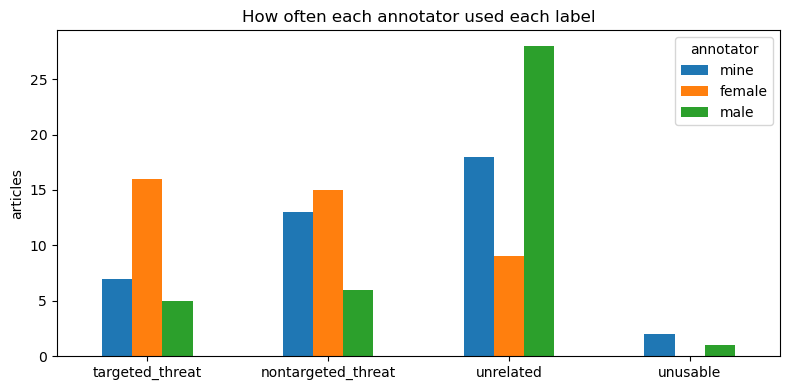

,mine,female,male
targeted_threat,7,16,5
nontargeted_threat,13,15,6
unrelated,18,9,28
unusable,2,0,1


In [4]:
usage = raters.apply(lambda col: col.value_counts()).reindex(LABELS).fillna(0).astype(int)

ax = usage.plot(kind="bar", figsize=(8, 4), color=["tab:blue", "tab:orange", "tab:green"])
ax.set_ylabel("articles")
ax.set_xlabel("")
ax.set_title("How often each annotator used each label")
ax.legend(title="annotator")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "round2_label_usage.png"), dpi=200)
plt.show()

usage

**What we see**

- The male reviewer called 28 of the 40 articles `unrelated`.
- The female reviewer called only 9 `unrelated` and used `targeted_threat` the most, 16 times.
- The student sits in between, with 18 `unrelated`.
- So the main split is not which kind of threat an article reports, but **whether it reports a threat at all**.

## Block 5: Where the disagreements fall

**This block checks whether the revision fixed what it was aimed at.** In the first round, half the disagreements were between `targeted_threat` and `nontargeted_threat`. Every disputed article is sorted by the boundary it fell on.

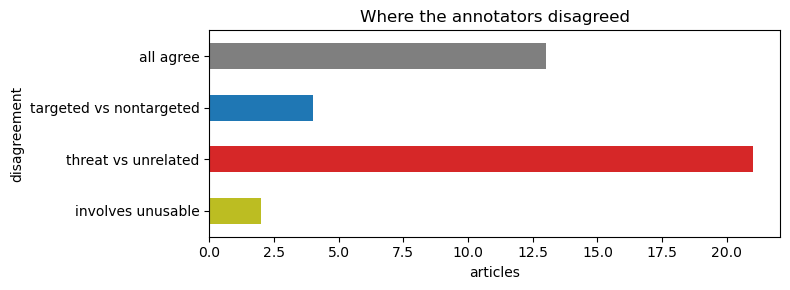

disagreement
all agree                  13
targeted vs nontargeted     4
threat vs unrelated        21
involves unusable           2
Name: count, dtype: int32

In [5]:
THREATS = {"targeted_threat", "nontargeted_threat"}


def disagreement_type(row):
    """Name the boundary the annotators disagreed on for one article."""
    found = set(row)
    if len(found) == 1:
        return "all agree"
    if found <= THREATS:
        return "targeted vs nontargeted"
    if "unrelated" in found and found & THREATS:
        return "threat vs unrelated"
    return "involves unusable"


labels["disagreement"] = raters.apply(disagreement_type, axis=1)
kinds = labels["disagreement"].value_counts().reindex(
    ["all agree", "targeted vs nontargeted", "threat vs unrelated", "involves unusable"]
).fillna(0).astype(int)

ax = kinds.plot(kind="barh", figsize=(8, 3), color=["tab:gray", "tab:blue", "tab:red", "tab:olive"])
ax.set_xlabel("articles")
ax.set_title("Where the annotators disagreed")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "round2_disagreement_types.png"), dpi=200)
plt.show()

kinds

**What we see**

- All three agreed on 13 of the 40 articles.
- Only 4 of the 27 disputed articles split between `targeted_threat` and `nontargeted_threat`. **The revision fixed the boundary it was aimed at.**
- 21 of the 27 split between a threat label and `unrelated`. The disagreement moved to a new boundary.

## Block 6: The fragile points

**This block finds the rule that broke.** Knowing which boundary fails is not enough to fix the codebook, so the 21 articles that split between a threat and `unrelated` are listed with their opening line. Reading them side by side shows what kind of article causes the split.

In [6]:
fragile = labels[labels["disagreement"] == "threat vs unrelated"].copy()
fragile["opening"] = fragile["preview"].str.slice(0, 110) + "..."

pd.set_option("display.max_colwidth", 120)
fragile[["id", "mine", "female", "male", "opening"]].reset_index(drop=True)

,id,mine,female,male,opening
0,103,targeted_threat,targeted_threat,unrelated,"ONALASKA, Wis. (WXOW) - Onalaska's Superintendent said in a letter to parents Tuesday afternoon that the threa..."
1,104,nontargeted_threat,nontargeted_threat,unrelated,"Poudre, Thompson school districts, police on watch after TikTok challenge encourages threats Schools and law e..."
2,105,unrelated,nontargeted_threat,unrelated,"Schools More Police In Stafford Schools Friday, But No Threat Found: PD The nationwide TikTok 'challenge' that..."
3,106,nontargeted_threat,targeted_threat,unrelated,"MUSKEGON, Mich. — The Muskegon County Prosecutor’s Office says eight more kids have been charged with making s..."
4,110,nontargeted_threat,nontargeted_threat,unrelated,"A threat spread by Tik Tok has many schools across the nation, and in Montana, having added police presence Fr..."
5,111,nontargeted_threat,nontargeted_threat,unrelated,"Schools step up security in response to threats on TikTok BONNEVILLE COUNTY, Idaho (AP) - Educators have annou..."
6,113,unrelated,nontargeted_threat,unrelated,Thompson School District Advises Parents of Potential Social Media Trend Threat to Schools Thompson School Dis...
7,114,unrelated,targeted_threat,unrelated,Rumor of weapon threat at Stewartville Middle School unfounded [anvplayer video=”5076564″ station=”998128″] (A...
8,115,nontargeted_threat,targeted_threat,unrelated,Heightened security at a Statesboro school after social media threat William James Middle School will remain o...
9,118,unrelated,targeted_threat,unrelated,"One Broward high school was under a Code Yellow lockdown for hours on Friday, and a student at another was det..."


**What we see**

There are two kinds of article behind the split.

- **Coverage of the viral trend itself (11 of the 21).** A school district adds security, or a superintendent warns parents, because of the TikTok post about December 17. The post was a threat aimed at every school, but nobody threatened that particular district. The codebook says this counts as `nontargeted_threat`, but the question at the top of the codebook, "Did someone make a threat?", leads people to answer no for that district and pick `unrelated`.
- **Threats that were rumored, unfounded or already in the courts (the other 10).** For example, article 114 reports a weapon rumor at Stewartville Middle School that turned out to be unfounded, and article 106 reports charges against students for earlier threats. The codebook says a false or rumored threat is still a threat, but several of these were marked `unrelated`. Article 103, a clear threat against Onalaska Middle School, was also marked `unrelated` by the male reviewer.

**These are the two fragile rules:** whether coverage of a viral trend counts when no single school was threatened, and whether a threat still counts once it is found to be false or has moved to the courts.

## Block 7: Build the labeled set for the baseline model

**This block prepares the next step.** The baseline model in notebook 07 needs one label per article. Both rounds are combined, each article keeps its majority label, and articles with no majority or a majority of `unusable` are left out, since a model cannot learn from an answer people could not agree on.

The class counts below also matter for the model. If one label is much rarer than the others, the model will tend to ignore it.

In [7]:
r1 = round1[["id", "url", "majority"]].assign(round=1)
r2 = labels[["id", "url", "majority"]].assign(round=2)

training = pd.concat([r1, r2], ignore_index=True).rename(columns={"majority": "label"})
training = training[training["label"].isin(LABELS[:3])]
training.to_csv(os.path.join(FOLDER, "labels_training.csv"), index=False)

print(len(training), "labeled articles saved to labels_training.csv")
pd.crosstab(training["label"], training["round"], margins=True, margins_name="total")

135 labeled articles saved to labels_training.csv


round,1,2,total
label,,,
nontargeted_threat,19,10,29
targeted_threat,48,8,56
unrelated,32,18,50
total,99,36,135


**What we see**

- 135 articles have a usable agreed label: 99 from the first round and 36 from the second.
- `targeted_threat` is the largest group and `nontargeted_threat` the smallest, but no label is rare enough to vanish. With this balance, three classes are workable for a baseline model.

## Round 2 conclusions

| Round | Articles | Labels | Fleiss kappa |
|---|---|---|---|
| Round 1, original codebook | 100 | 3 | 0.575 |
| Round 2, revised codebook | 40 | 4 | 0.274 |
| Round 2, three original labels only | 38 | 3 | 0.277 |

**The revision fixed the problem it targeted, and exposed a bigger one.** Confusion between `targeted_threat` and `nontargeted_threat` fell to 4 of the 27 disputed articles. But 21 now split on whether the article reports a threat at all.

**Two rules are fragile.** The first is coverage of the viral trend itself: a district adding security or warning parents because of a threat aimed at every school. The codebook classifies it as `nontargeted_threat`, but its opening question pushes people toward `unrelated`. The second is a threat that was later found to be false, or that is reported through the charges that followed it. The codebook counts both as threats, but people did not apply that consistently.

**One reviewer accounts for much of the drop.** The male reviewer labeled 28 of 40 articles `unrelated`, and the two reviewers agreed on only 38 percent.

**What happens next**

1. The codebook's opening question is rewritten so that coverage of a viral threat trend clearly counts even when no single school is named, and so that a false or rumored threat, or the charges that follow one, still counts as a threat.
2. The baseline model trains on the 135 articles in `labels_training.csv`, and the agreement level is reported as a limitation.
3. The model's mistakes are compared with the human ones. If the model struggles on the same trend-coverage articles, that confirms the difficulty is in the task and not only in the people.